# Economic Growth and Per-Capita CO₂ Decoupling in East Asia

**CISC7204 · Class B · Team 01**

How did real GDP per person and territorial CO₂ emissions per person move in China, Japan, and South Korea from 2000 to 2022? We trace annual changes, classify decoupling in three periods, and check how the full-period result responds to different endpoints.

The indicators are real GDP in constant 2015 US dollars per person and CO₂ from fossil fuels and industrial processes in tonnes per person. Sources: [World Bank WDI](https://data.worldbank.org/indicator/NY.GDP.PCAP.KD) and [OWID CO₂ data](https://github.com/owid/co2-data).

## 1. Read and filter the source data

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAW = Path('data/raw/snapshot_2026-11-05')
PROCESSED = Path('data/processed')
PROCESSED.mkdir(parents=True, exist_ok=True)

GDP = 'gdp_per_capita_constant_2015_usd'
CO2 = 'co2_per_capita_tonnes'
countries = {'CHN': 'China', 'JPN': 'Japan', 'KOR': 'South Korea'}
country_files = {'CHN': 'china', 'JPN': 'japan', 'KOR': 'south_korea'}

In [2]:
co2 = pd.read_csv(RAW / 'owid-co2-data.csv',
                  usecols=['iso_code', 'country', 'year', 'co2_per_capita'])
co2 = co2[co2['iso_code'].isin(countries) & co2['year'].between(2000, 2022)].copy()
co2 = co2.rename(columns={'country': 'owid_country', 'co2_per_capita': CO2})

with open(RAW / 'worldbank_gdp_per_capita.json', encoding='utf-8') as f:
    wb = json.load(f)

print('World Bank metadata:', wb[0])
assert wb[0]['pages'] == 1, 'Check whether the API response has more pages.'
rows = []
for item in wb[1]:
    rows.append({
        'iso_code': item['countryiso3code'],
        'year': int(item['date']),
        'wb_country': item['country']['value'],
        GDP: item['value']
    })
gdp = pd.DataFrame(rows)
gdp = gdp[gdp['iso_code'].isin(countries) & gdp['year'].between(2000, 2022)].copy()
gdp[GDP] = pd.to_numeric(gdp[GDP])
co2[CO2] = pd.to_numeric(co2[CO2])
display(co2.head())
display(gdp.head())

World Bank metadata: {'page': 1, 'pages': 1, 'per_page': 1000, 'total': 69, 'sourceid': '2', 'lastupdated': '2026-10-08'}


,owid_country,year,iso_code,co2_per_capita_tonnes
9909,China,2000,CHN,2.870
9910,China,2001,CHN,2.912
9911,China,2002,CHN,3.185
9912,China,2003,CHN,3.735
9913,China,2004,CHN,4.002


,iso_code,year,wb_country,gdp_per_capita_constant_2015_usd
0,CHN,2022,China,11830.298768
1,CHN,2021,China,11469.317451
2,CHN,2020,China,10573.379406
3,CHN,2019,China,10356.292489
4,CHN,2018,China,9798.578906


## 2. Join and verify the country-year panel

The outer merge exposes any unmatched keys. The checks require one matched row per country and year, 23 years per country, and complete GDP and CO₂ values.

In [3]:
keys = ['iso_code', 'year']
assert not co2.duplicated(keys).any(), 'Duplicate CO2 country-year keys.'
assert not gdp.duplicated(keys).any(), 'Duplicate GDP country-year keys.'

# Keep unmatched keys visible and require one row per country and year.
panel = pd.merge(co2, gdp, on=keys, how='outer', validate='one_to_one', indicator=True)
print('Match counts')
print(panel['_merge'].value_counts())
print('Missing values')
print(panel[[GDP, CO2]].isna().sum())

assert panel['_merge'].eq('both').all(), 'The sources have unmatched keys.'
assert panel.groupby('iso_code')['year'].nunique().to_dict() == {'CHN': 23, 'JPN': 23, 'KOR': 23}
assert len(panel) == 69, 'Expected 69 country-year records.'
assert panel[[GDP, CO2]].notna().all().all(), 'GDP or CO2 has missing observations.'
assert panel[GDP].gt(0).all() and panel[CO2].ge(0).all(), 'GDP must be positive and CO2 nonnegative.'

panel['country'] = panel['iso_code'].map(countries)
panel['gdp_source_indicator'] = 'NY.GDP.PCAP.KD'
panel['co2_source_variable'] = 'co2_per_capita'
panel = panel[['iso_code', 'country', 'year', GDP, CO2, 'owid_country', 'wb_country',
               'gdp_source_indicator', 'co2_source_variable']]
panel = panel.sort_values(keys).reset_index(drop=True)
panel.to_csv(PROCESSED / 'east_asia_master_2000_2022.csv', index=False)
display(panel.head())
print(f"Data checks passed: {len(panel)} country-year records.")

Match counts
_merge
both          69
left_only      0
right_only     0
Name: count, dtype: int64
Missing values
gdp_per_capita_constant_2015_usd    0
co2_per_capita_tonnes               0
dtype: int64


,iso_code,country,year,gdp_per_capita_constant_2015_usd,co2_per_capita_tonnes,owid_country,wb_country,gdp_source_indicator,co2_source_variable
0,CHN,China,2000,2237.300479,2.870,China,China,NY.GDP.PCAP.KD,co2_per_capita
1,CHN,China,2001,2405.994119,2.912,China,China,NY.GDP.PCAP.KD,co2_per_capita
2,CHN,China,2002,2610.662751,3.185,China,China,NY.GDP.PCAP.KD,co2_per_capita
3,CHN,China,2003,2856.850533,3.735,China,China,NY.GDP.PCAP.KD,co2_per_capita
4,CHN,China,2004,3127.914449,4.002,China,China,NY.GDP.PCAP.KD,co2_per_capita


Data checks passed: 69 country-year records.


## 3. Calculate annual indicators

Set each country's two series to 100 in 2000 to compare proportional changes. Year-over-year growth starts in 2001. The CO₂/GDP ratio is an emissions-intensity proxy in kg CO₂ per constant 2015 US dollar.

In [4]:
annual_by_country = {}
for country_code, file_name in country_files.items():
    annual = panel[panel['iso_code'] == country_code].copy().set_index('year').sort_index()
    assert annual.loc[2000, CO2] > 0, 'The 2000 CO2 value must be positive.'
    annual['gdp_index_2000_100'] = annual[GDP] / annual.loc[2000, GDP] * 100
    annual['co2_index_2000_100'] = annual[CO2] / annual.loc[2000, CO2] * 100
    annual['gdp_yoy_pct'] = annual[GDP].pct_change(fill_method=None) * 100
    annual['co2_yoy_pct'] = annual[CO2].pct_change(fill_method=None) * 100
    annual['intensity_proxy_kg_per_usd'] = annual[CO2] / annual[GDP] * 1000
    annual_by_country[country_code] = annual
    annual.to_csv(PROCESSED / f'{file_name}_annual_indicators.csv')
    print(countries[country_code])
    display(annual[[GDP, CO2, 'gdp_index_2000_100', 'co2_index_2000_100']].round(2))

China


,gdp_per_capita_constant_2015_usd,co2_per_capita_tonnes,gdp_index_2000_100,co2_index_2000_100
year,,,,
2000,2237.30,2.87,100.00,100.00
2001,2405.99,2.91,107.54,101.46
2002,2610.66,3.18,116.69,110.98
2003,2856.85,3.74,127.69,130.14
2004,3127.91,4.00,139.81,139.44
2005,3465.73,4.49,154.91,156.45
2006,3883.27,4.92,173.57,171.46
2007,4409.70,5.26,197.10,183.31
2008,4811.34,5.62,215.05,195.71


Japan


,gdp_per_capita_constant_2015_usd,co2_per_capita_tonnes,gdp_index_2000_100,co2_index_2000_100
year,,,,
2000,31779.38,9.92,100.00,100.00
2001,31793.13,9.79,100.04,98.68
2002,31746.24,10.01,99.90,100.85
2003,32115.58,10.06,101.06,101.36
2004,32783.13,10.01,103.16,100.88
2005,33385.92,10.06,105.06,101.37
2006,33880.69,9.87,106.61,99.50
2007,34426.69,10.14,108.33,102.22
2008,34008.59,9.59,107.01,96.63


South Korea


,gdp_per_capita_constant_2015_usd,co2_per_capita_tonnes,gdp_index_2000_100,co2_index_2000_100
year,,,,
2000,17763.14,9.41,100.00,100.00
2001,18460.43,9.68,103.93,102.94
2002,19775.38,10.06,111.33,106.98
2003,20278.04,10.21,114.16,108.55
2004,21244.81,10.30,119.60,109.50
2005,22123.76,10.42,124.55,110.78
2006,23162.19,10.49,130.39,111.48
2007,24391.77,10.83,137.32,115.10
2008,24934.54,11.02,140.37,117.08


## 4. Classify decoupling by period

Cumulative growth is 100 × (end ÷ start − 1). We compare 2000–2022 with its two subperiods, 2000–2010 and 2010–2022. The subperiods cover different lengths and share the 2010 endpoint.

| Rule | Category |
|---|---|
| GDP rises and CO₂ falls | Absolute per-capita decoupling |
| GDP rises and CO₂ is flat or grows more slowly | Relative per-capita decoupling |
| GDP rises and CO₂ grows at least as fast | No decoupling during growth |
| GDP is flat or falls | No positive income growth |

In [5]:
def calculate_growth(start, end, label):
    g = (end[GDP] / start[GDP] - 1) * 100
    c = (end[CO2] / start[CO2] - 1) * 100

    # Classify with full precision. Round only for display.
    if g <= 0:
        category = 'No positive income growth'
    elif c < 0:
        category = 'Absolute per-capita decoupling'
    elif c < g:
        category = 'Relative per-capita decoupling'
    else:
        category = 'No decoupling during growth'

    return {
        'period': label,
        'gdp_growth_pct': g,
        'co2_growth_pct': c,
        'intensity_change_pct': ((end[CO2] / end[GDP]) / (start[CO2] / start[GDP]) - 1) * 100,
        'classification': category
    }

periods_by_country = {}
for country_code, file_name in country_files.items():
    annual = annual_by_country[country_code]
    results = []
    for start_year, end_year in [(2000, 2022), (2000, 2010), (2010, 2022)]:
        result = calculate_growth(annual.loc[start_year], annual.loc[end_year],
                                  f'{start_year}-{end_year}')
        results.append(result)
    periods = pd.DataFrame(results)
    output_dir = Path('output') / f'{file_name}_analysis'
    output_dir.mkdir(parents=True, exist_ok=True)
    periods.to_csv(output_dir / f'{file_name}_period_growth.csv', index=False)
    periods_by_country[country_code] = periods

In [6]:
period_comparison = pd.concat(periods_by_country, names=['iso_code'])
period_comparison = period_comparison.reset_index(level='iso_code').reset_index(drop=True)
period_comparison.insert(1, 'country', period_comparison['iso_code'].map(countries))
period_comparison.to_csv('output/east_asia_period_growth.csv', index=False)
display(period_comparison.round(2))

,iso_code,country,period,gdp_growth_pct,co2_growth_pct,intensity_change_pct,classification
0,CHN,China,2000-2022,428.78,186.34,-45.85,Relative per-capita decoupling
1,CHN,China,2000-2010,157.66,121.95,-13.86,Relative per-capita decoupling
2,CHN,China,2010-2022,105.22,29.01,-37.14,Relative per-capita decoupling
3,JPN,Japan,2000-2022,17.84,-16.97,-29.54,Absolute per-capita decoupling
4,JPN,Japan,2000-2010,4.82,-4.77,-9.15,Absolute per-capita decoupling
5,JPN,Japan,2010-2022,12.42,-12.82,-22.45,Absolute per-capita decoupling
6,KOR,South Korea,2000-2022,101.59,24.57,-38.20,Relative per-capita decoupling
7,KOR,South Korea,2000-2010,49.88,29.54,-13.57,Relative per-capita decoupling
8,KOR,South Korea,2010-2022,34.50,-3.83,-28.50,Absolute per-capita decoupling


## 5. Check sensitivity to the choice of endpoints

Compare the baseline with a 2019 endpoint and with three-year averages at both ends. For the latter, average each indicator in 2000–2002 and 2020–2022 before calculating growth.

In [7]:
sensitivity_by_country = {}
for country_code, file_name in country_files.items():
    annual = annual_by_country[country_code]
    start_average = annual.loc[2000:2002, [GDP, CO2]].mean()
    end_average = annual.loc[2020:2022, [GDP, CO2]].mean()
    sensitivity = pd.DataFrame([
        calculate_growth(annual.loc[2000], annual.loc[2022], '2000-2022'),
        calculate_growth(annual.loc[2000], annual.loc[2019], '2000-2019'),
        calculate_growth(start_average, end_average, '2000-02 mean -> 2020-22 mean')
    ])
    sensitivity['category_changed_vs_baseline'] = sensitivity['classification'] != sensitivity.loc[0, 'classification']
    output_dir = Path('output') / f'{file_name}_analysis'
    sensitivity.to_csv(output_dir / f'{file_name}_endpoint_sensitivity.csv', index=False)
    sensitivity_by_country[country_code] = sensitivity

In [8]:
sensitivity_comparison = pd.concat(sensitivity_by_country, names=['iso_code'])
sensitivity_comparison = sensitivity_comparison.reset_index(level='iso_code').reset_index(drop=True)
sensitivity_comparison.insert(1, 'country', sensitivity_comparison['iso_code'].map(countries))
sensitivity_comparison.to_csv('output/east_asia_endpoint_sensitivity.csv', index=False)
display(sensitivity_comparison.round(2))

,iso_code,country,period,gdp_growth_pct,co2_growth_pct,intensity_change_pct,classification,category_changed_vs_baseline
0,CHN,China,2000-2022,428.78,186.34,-45.85,Relative per-capita decoupling,False
1,CHN,China,2000-2019,362.89,162.23,-43.35,Relative per-capita decoupling,False
2,CHN,China,2000-02 mean -> 2020-22 mean,366.96,165.08,-43.23,Relative per-capita decoupling,False
3,JPN,Japan,2000-2022,17.84,-16.97,-29.54,Absolute per-capita decoupling,False
4,JPN,Japan,2000-2019,15.92,-12.33,-24.37,Absolute per-capita decoupling,False
5,JPN,Japan,2000-02 mean -> 2020-22 mean,14.99,-16.30,-27.21,Absolute per-capita decoupling,False
6,KOR,South Korea,2000-2022,101.59,24.57,-38.20,Relative per-capita decoupling,False
7,KOR,South Korea,2000-2019,88.57,32.66,-29.65,Relative per-capita decoupling,False
8,KOR,South Korea,2000-02 mean -> 2020-22 mean,85.39,20.47,-35.02,Relative per-capita decoupling,False


## 6. Visual evidence and design choices

The notes following each figure group answer the five assignment prompts and apply Alberto Cairo's discussion of visualization quality in [The Truthful Art (2016)](https://www.oreilly.com/library/view/the-truthful-art/9780133440492/ch00.html). Country panels share encodings and have individually fitted axis ranges. Use labeled values and the combined tables for numeric comparisons across countries.

In [9]:
BLUE, ORANGE = '#0072B2', '#B34F00'
source_note = 'Sources: World Bank WDI; OWID CO2 dataset. Saved snapshot: see data/raw/.'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

### 6.1 Observed levels

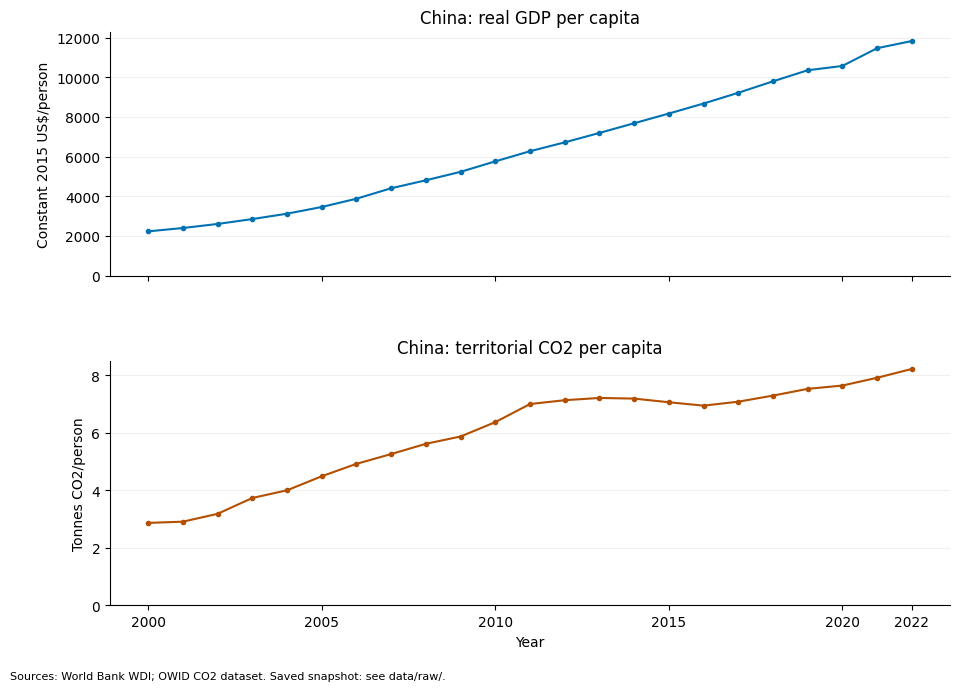

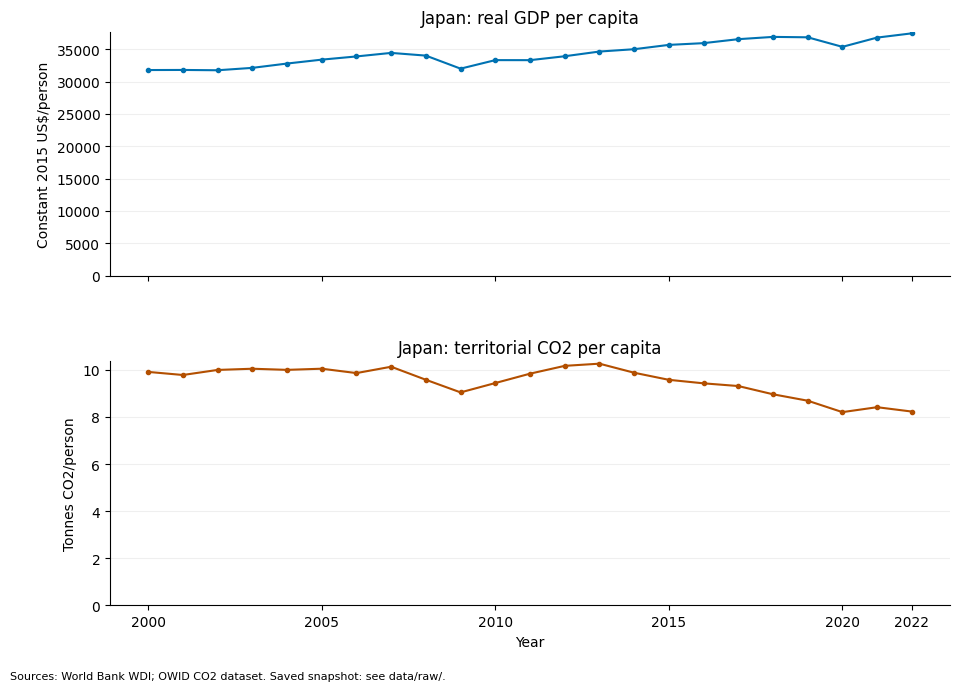

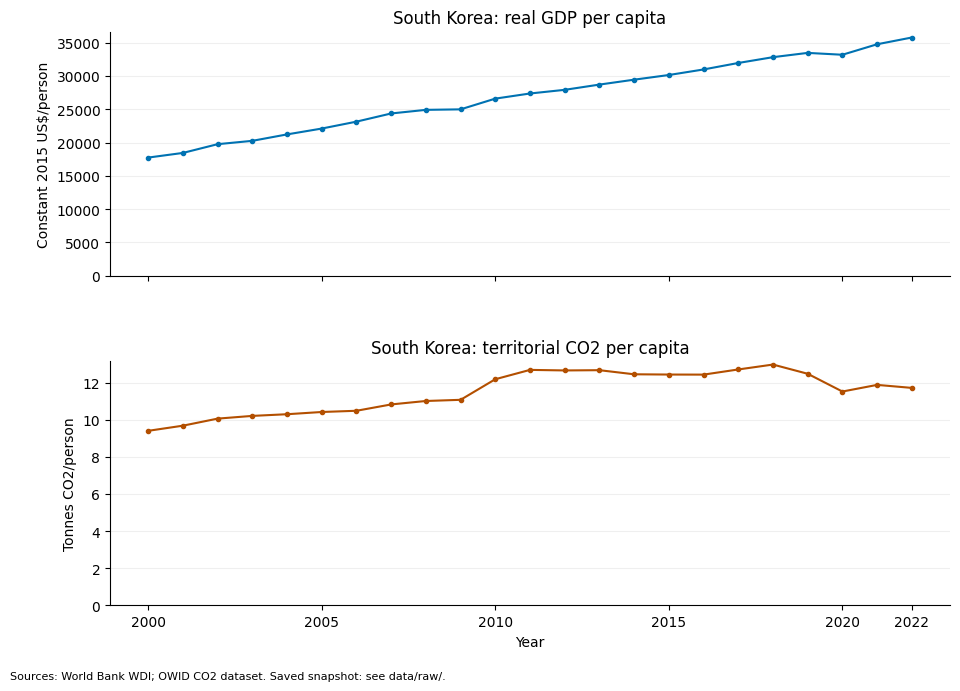

In [10]:
for country_code, file_name in country_files.items():
    country_name = countries[country_code]
    figure_dir = Path('output') / f'{file_name}_analysis' / 'figures'
    figure_dir.mkdir(parents=True, exist_ok=True)
    country_data = annual_by_country[country_code].reset_index()
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    for ax, col, color, title, unit in [
        (axes[0], GDP, BLUE, f'{country_name}: real GDP per capita', 'Constant 2015 US$/person'),
        (axes[1], CO2, ORANGE, f'{country_name}: territorial CO2 per capita', 'Tonnes CO2/person')]:
        ax.plot(country_data.year, country_data[col], color=color, marker='o', markersize=3)
        ax.set(title=title, ylabel=unit, ylim=(0, None))
        ax.grid(axis='y', alpha=.2)
    axes[1].set(xlabel='Year', xticks=[2000,2005,2010,2015,2020,2022])
    fig.subplots_adjust(left=.12, right=.96, top=.94, bottom=.12, hspace=.35)
    fig.text(0.02, 0.015, source_note, fontsize=8)
    fig.savefig(figure_dir / f'01_{file_name}_levels.png', dpi=200)
    fig.savefig(figure_dir / f'01_{file_name}_levels.svg')
    plt.show()
    plt.close(fig)

1. **Design guideline.** Use aligned time axes and separate, zero-based value axes for the two units.
2. **Truthful.** Dots mark annual observations, lines connect them in time order, and the axes explicitly name constant dollars per person and tonnes per person. The footer names the data sources.
3. **Functional.** Stacking the panels makes it easy to find the same date and read each measure on its own scale.
4. **Beautiful.** Consistent marker sizes, restrained gridlines, and aligned panels give the two series a clear visual hierarchy.
5. **Insightful.** China ends 2022 higher on both measures than in 2000, while Japan ends with lower CO₂ per person despite higher real GDP per person.

### 6.2 Indexed trends

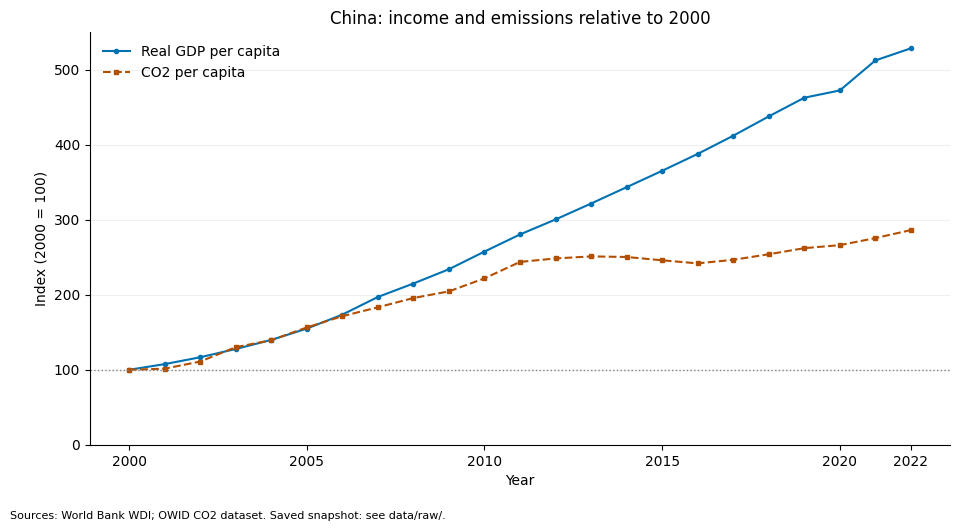

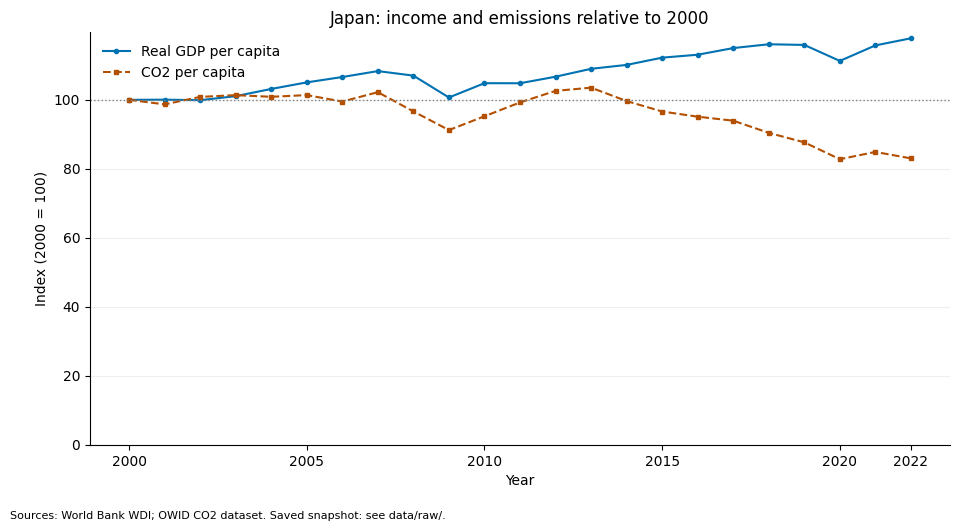

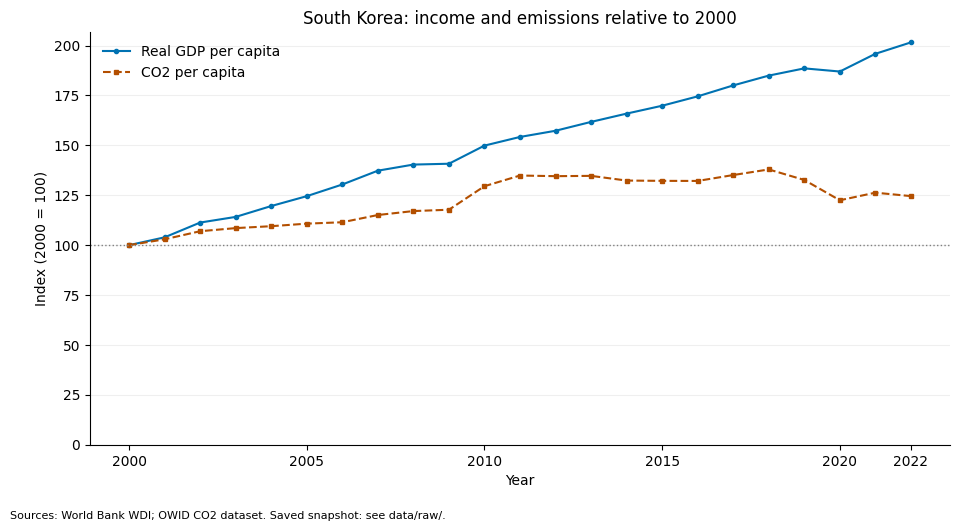

In [11]:
for country_code, file_name in country_files.items():
    country_name = countries[country_code]
    figure_dir = Path('output') / f'{file_name}_analysis' / 'figures'
    figure_dir.mkdir(parents=True, exist_ok=True)
    country_data = annual_by_country[country_code].reset_index()
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(country_data.year, country_data.gdp_index_2000_100, color=BLUE, marker='o', markersize=3, label='Real GDP per capita')
    ax.plot(country_data.year, country_data.co2_index_2000_100, color=ORANGE, linestyle='--', marker='s', markersize=3, label='CO2 per capita')
    ax.axhline(100, color='gray', linestyle=':', linewidth=1)
    ax.set(title=f'{country_name}: income and emissions relative to 2000', ylabel='Index (2000 = 100)',
           xlabel='Year', xticks=[2000,2005,2010,2015,2020,2022], ylim=(0,None))
    ax.grid(axis='y', alpha=.2)
    ax.legend(frameon=False)
    fig.subplots_adjust(left=.1, right=.96, top=.9, bottom=.15)
    fig.text(0.02, 0.015, source_note, fontsize=8)
    fig.savefig(figure_dir / f'02_{file_name}_indexed_trends.png', dpi=200)
    fig.savefig(figure_dir / f'02_{file_name}_indexed_trends.svg')
    plt.show()
    plt.close(fig)

1. **Design guideline.** Use a common index and a shared axis within each country to compare proportional changes across different units.
2. **Truthful.** The axis and dotted line identify 100 as the 2000 baseline. Both series use the same formula with their own starting values.
3. **Functional.** Solid circles and dashed squares make the two paths distinguishable by shape and line style as well as color.
4. **Beautiful.** A limited palette and low-contrast grid keep attention on the two paths and their baseline.
5. **Insightful.** China's GDP index pulls ahead while CO₂ remains above 100 by 2022. Japan's GDP ends above the baseline and its CO₂ below it.

### 6.3 Period growth and decoupling

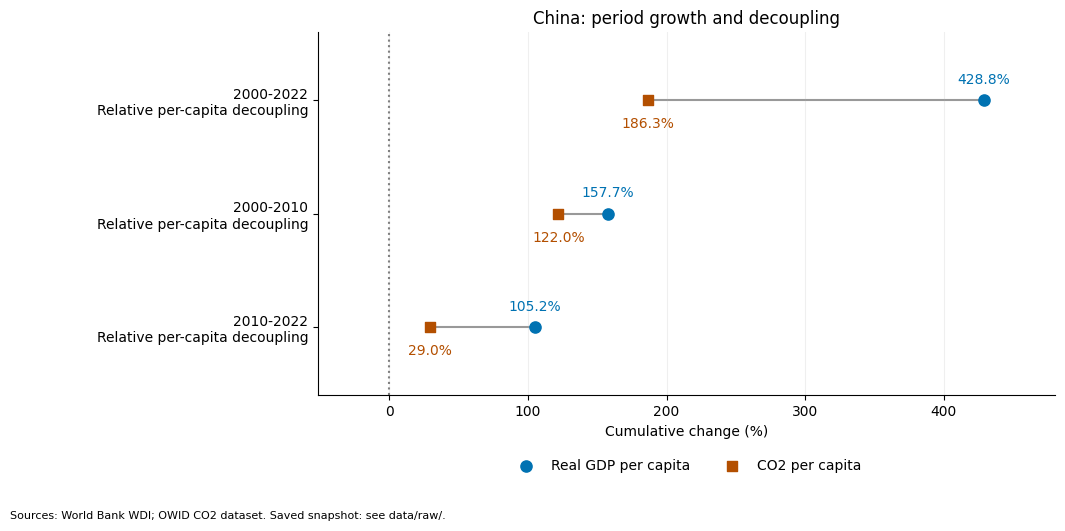

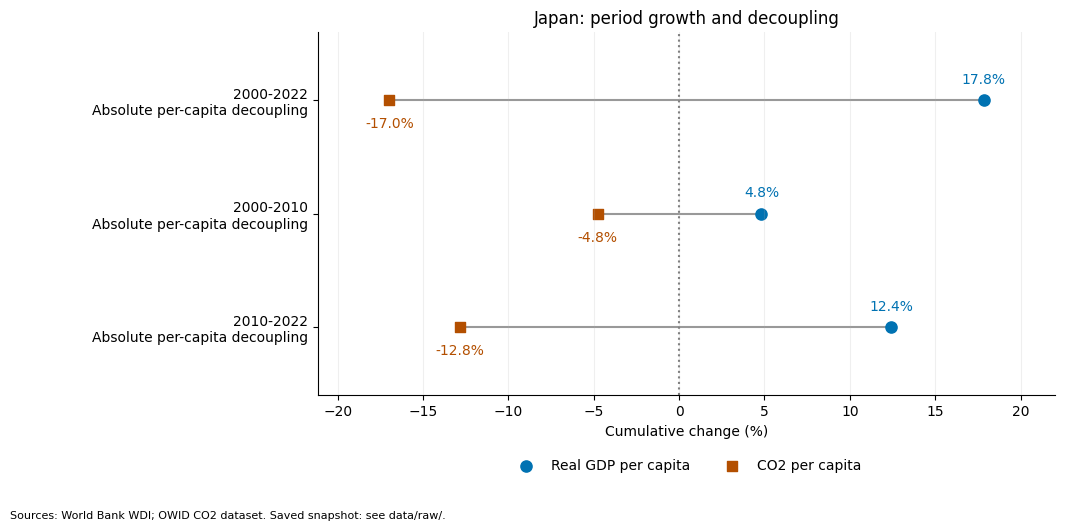

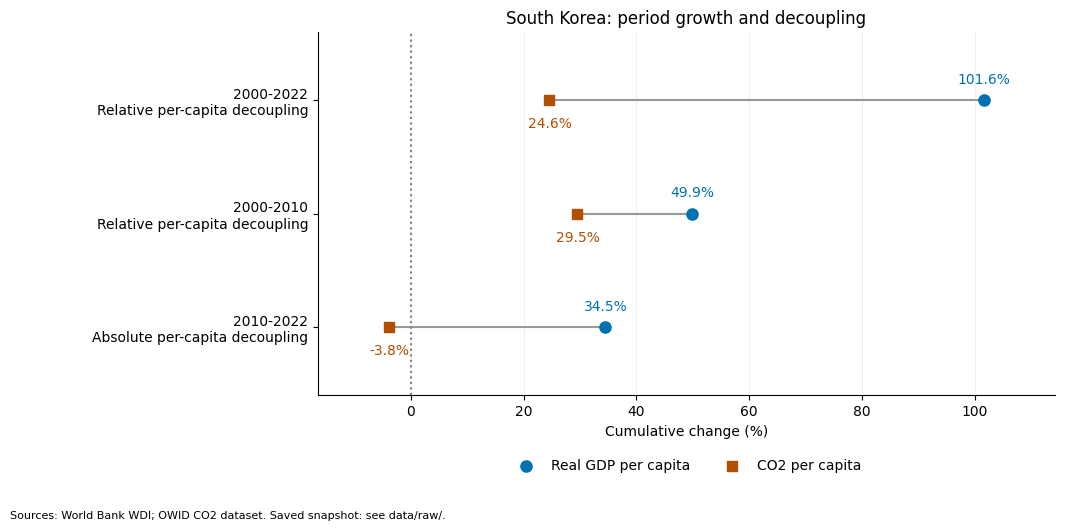

In [12]:
for country_code, file_name in country_files.items():
    country_name = countries[country_code]
    figure_dir = Path('output') / f'{file_name}_analysis' / 'figures'
    figure_dir.mkdir(parents=True, exist_ok=True)
    periods = periods_by_country[country_code]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    for i, row in periods.iterrows():
        ax.plot([row.gdp_growth_pct, row.co2_growth_pct], [i,i], color='#999999', zorder=1)
        ax.scatter(row.gdp_growth_pct, i, color=BLUE, marker='o', s=65, label='Real GDP per capita' if i==0 else None)
        ax.scatter(row.co2_growth_pct, i, color=ORANGE, marker='s', s=60, label='CO2 per capita' if i==0 else None)
        ax.annotate(f'{row.gdp_growth_pct:.1f}%', (row.gdp_growth_pct,i), xytext=(0,12), textcoords='offset points', ha='center', color=BLUE)
        ax.annotate(f'{row.co2_growth_pct:.1f}%', (row.co2_growth_pct,i), xytext=(0,-20), textcoords='offset points', ha='center', color=ORANGE)
    ax.axvline(0, color='gray', linestyle=':')
    ax.set(yticks=range(len(periods)), yticklabels=[f'{r.period}\n{r.classification}' for _,r in periods.iterrows()],
           xlabel='Cumulative change (%)', title=f'{country_name}: period growth and decoupling', ylim=(-.6,2.6))
    ax.invert_yaxis()
    ax.margins(x=.12)
    ax.grid(axis='x', alpha=.2)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.14), ncol=2, frameon=False)
    fig.subplots_adjust(left=.30, right=.97, top=.90, bottom=.24)
    fig.text(0.02, 0.015, source_note, fontsize=8)
    fig.savefig(figure_dir / f'03_{file_name}_period_growth.png', dpi=200)
    fig.savefig(figure_dir / f'03_{file_name}_period_growth.svg')
    plt.show()
    plt.close(fig)

1. **Design guideline.** Paired dots encode signed percentage changes by position on one axis, with an explicit zero reference.
2. **Truthful.** Each row states the exact years and both cumulative changes. Negative values fall to the left of zero. Classifications use the unrounded values.
3. **Functional.** The pairing shows which measure grew faster, and each row gives the corresponding category.
4. **Beautiful.** A light connector groups the markers, with blue circles and orange squares as the focal points. The value labels sit above and below their row.
5. **Insightful.** South Korea's CO₂ moves from a 29.54% increase in 2000–2010 to a 3.83% decrease in 2010–2022. GDP grows in both periods, which explains the switch from relative to absolute decoupling.

### 6.4 Income–emissions trajectories

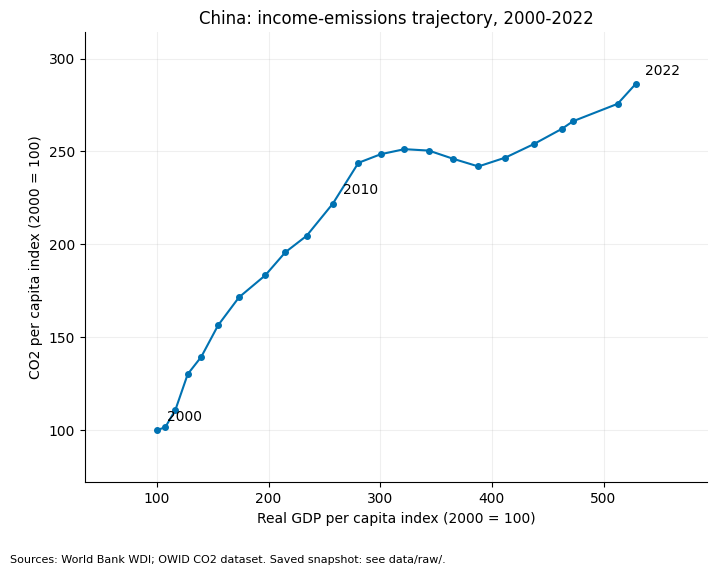

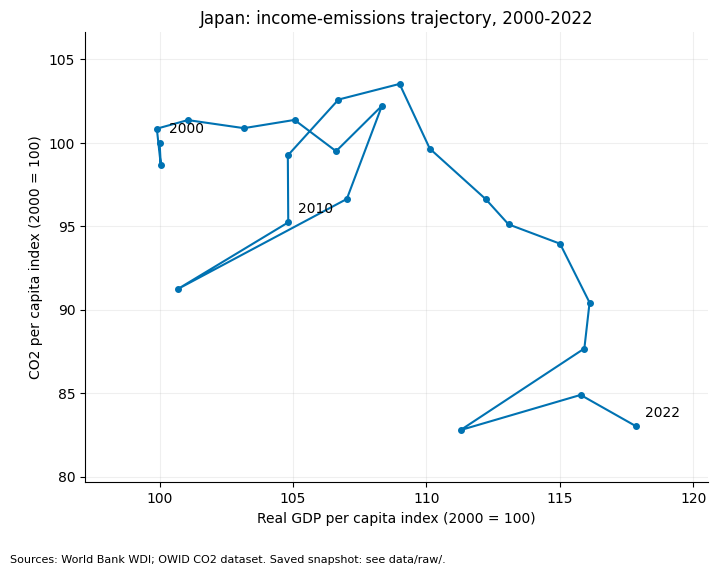

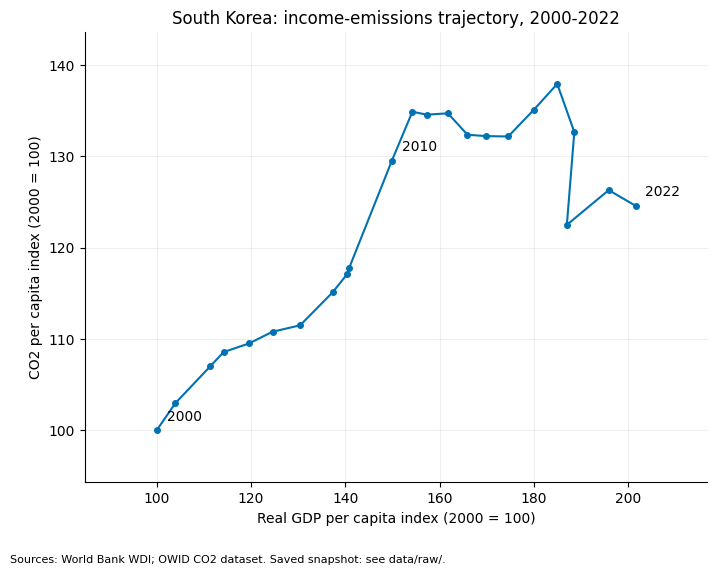

In [13]:
for country_code, file_name in country_files.items():
    country_name = countries[country_code]
    figure_dir = Path('output') / f'{file_name}_analysis' / 'figures'
    figure_dir.mkdir(parents=True, exist_ok=True)
    country_data = annual_by_country[country_code].reset_index()
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.plot(country_data.gdp_index_2000_100, country_data.co2_index_2000_100, color=BLUE, marker='o', markersize=4)
    for year in [2000,2010,2022]:
        r = country_data.loc[country_data.year.eq(year)].iloc[0]
        ax.annotate(str(year), (r.gdp_index_2000_100,r.co2_index_2000_100), xytext=(7,7), textcoords='offset points')
    ax.set(title=f'{country_name}: income-emissions trajectory, 2000-2022', xlabel='Real GDP per capita index (2000 = 100)',
           ylabel='CO2 per capita index (2000 = 100)')
    ax.margins(.15)
    ax.grid(alpha=.2)
    fig.subplots_adjust(left=.12, right=.95, top=.90, bottom=.15)
    fig.text(0.02, 0.015, source_note, fontsize=8)
    fig.savefig(figure_dir / f'04_{file_name}_growth_path.png', dpi=200)
    fig.savefig(figure_dir / f'04_{file_name}_growth_path.svg')
    plt.show()
    plt.close(fig)

1. **Design guideline.** Use two labeled index axes for joint movement and label the years that delimit the study periods.
2. **Truthful.** Each dot is one annual observation, and the segments are drawn in chronological order. The index units and axis ranges are explicit, so readers can see that a segment's angle depends on both scales.
3. **Functional.** Moving right indicates higher GDP and moving down indicates lower emissions. Labels identify 2000, 2010, and 2022.
4. **Beautiful.** One path color, small markers, and a few year labels keep attention on the trajectory.
5. **Insightful.** South Korea's 2022 point is right of and below 2010 but above its 2000 emissions baseline. This links its later absolute result with its full-period relative result.

### 6.5 Endpoint sensitivity tables

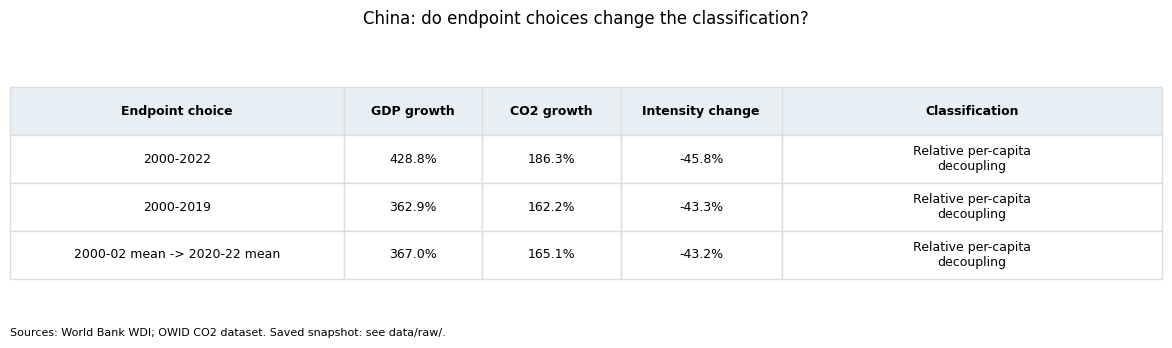

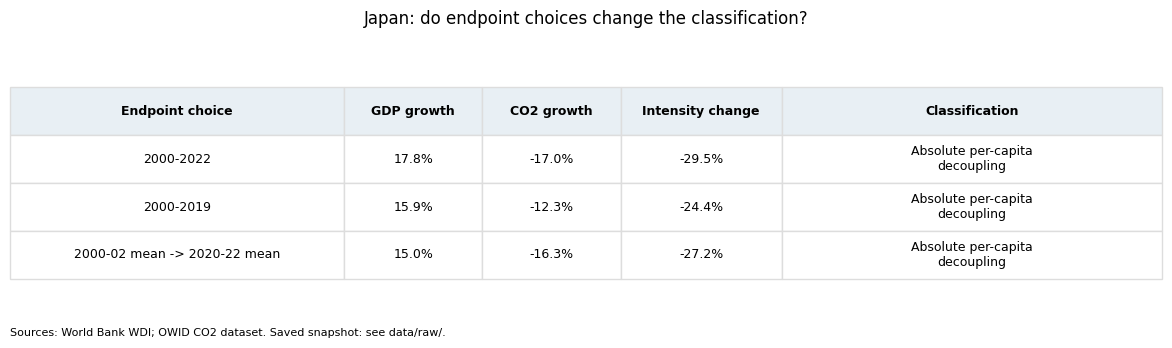

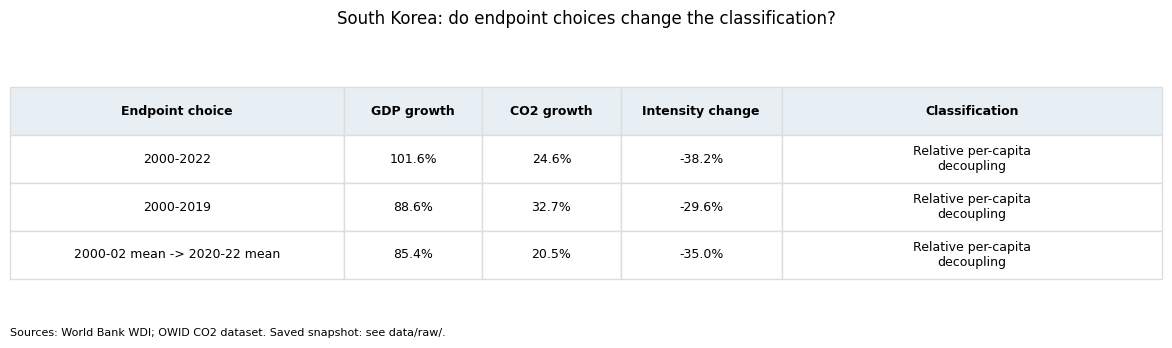

In [14]:
for country_code, file_name in country_files.items():
    country_name = countries[country_code]
    figure_dir = Path('output') / f'{file_name}_analysis' / 'figures'
    figure_dir.mkdir(parents=True, exist_ok=True)
    sensitivity = sensitivity_by_country[country_code]
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.axis('off')
    rows = [[r.period, f'{r.gdp_growth_pct:.1f}%', f'{r.co2_growth_pct:.1f}%',
             f'{r.intensity_change_pct:.1f}%', r.classification.replace('per-capita ', 'per-capita\n')]
            for _,r in sensitivity.iterrows()]
    tbl = ax.table(cellText=rows, colLabels=['Endpoint choice', 'GDP growth', 'CO2 growth', 'Intensity change', 'Classification'],
                   colWidths=[.29,.12,.12,.14,.33], cellLoc='center', bbox=[0,.08,1,.74])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    for (r,c), cell in tbl.get_celld().items():
        cell.set_text_props(color='black')
        cell.set_edgecolor('#DDDDDD')
        if r==0:
            cell.set_facecolor('#E8EFF4')
            cell.set_text_props(weight='bold')
    ax.set_title(f'{country_name}: do endpoint choices change the classification?', pad=12)
    fig.subplots_adjust(left=.02, right=.98, top=.86, bottom=.12)
    fig.text(0.02, 0.015, source_note, fontsize=8)
    fig.savefig(figure_dir / f'05_{file_name}_endpoint_sensitivity.png', dpi=200)
    fig.savefig(figure_dir / f'05_{file_name}_endpoint_sensitivity.svg')
    plt.show()
    plt.close(fig)

1. **Design guideline.** Use aligned columns when exact numbers and text categories are the main comparison.
2. **Truthful.** The rows specify the years or averaging windows and show growth in percent. The same growth formulas and classification rules apply to all rows.
3. **Functional.** Readers can scan the final column for a category change and trace that category back to GDP and CO₂ growth in the same row.
4. **Beautiful.** Header shading, light borders, and consistent decimal precision make the three cases easy to scan.
5. **Insightful.** The numbers move when endpoints change, but Japan stays absolute and China and South Korea stay relative in both alternative scenarios.

## 7. Findings and scope

| Economy | GDP per person, 2000–2022 | CO₂ per person, 2000–2022 | Pattern |
|---|---:|---:|---|
| China | +428.78% | +186.34% | Relative in both subperiods and in the full period |
| Japan | +17.84% | −16.97% | Absolute in both subperiods and in the full period |
| South Korea | +101.59% | +24.57% | Relative in 2000–2010, absolute in 2010–2022, and relative in the full period |

Both alternative endpoint choices preserve the full-period category for all three countries. China and South Korea illustrate how relative decoupling can coexist with more emissions per person. The results describe territorial CO₂ per person and real GDP per person. Total emissions, consumption-based emissions, and causal effects require different evidence.